# Comparación de umbrales de faltantes para selección de variables

Comparamos umbrales máximos de faltantes de 10%, 30%, 50% y 75% para regresión logística, SVM lineal y Gradient Boosting. La selección se recalcula dentro del entrenamiento de cada corte; no se fija una cantidad de variables.

## 1. Diseño y control temporal

Los cortes son entrenamiento hasta 2012 → validación 2013, hasta 2013 → 2014, hasta 2014 → 2015 y hasta 2015 → 2016. Se evaluarán 48 ajustes: 3 modelos × 4 umbrales × 4 cortes.

En cada corte se calcula el porcentaje de faltantes en el entrenamiento, y se incluyen variables con porcentaje **menor o igual** al umbral. Esa misma lista se aplica al año de validación. Las observaciones son idénticas entre experimentos. No se incluyen préstamos de 2017 en adelante.

Las candidatas parten de las reglas de disponibilidad al otorgamiento ya usadas en el proyecto: se excluyen identificadores, texto libre, códigos fuera de alcance, variables posteriores al otorgamiento y variables de precio de Lending Club. Se conservan solamente predictores que podrían estar disponibles al solicitar el préstamo. El notebook muestra la lista de exclusiones y motivos.

Los faltantes numéricos se imputan con mediana del entrenamiento, sin indicadores. Las categóricas se completan con «Sin información» y se codifican. Regresión logística y SVM usan escalado sin centrar para preservar matrices dispersas. Gradient Boosting usa la misma mediana y categorías, escalado centrado y matriz densa, como en búsquedas anteriores. Todas las transformaciones se ajustan solo con entrenamiento.

In [1]:
from pathlib import Path
import sys,time,gc,warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from scipy import sparse
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder,StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score,average_precision_score
from sklearn.exceptions import ConvergenceWarning

RAIZ=Path.cwd()
if not (RAIZ/"src").exists(): RAIZ=RAIZ.parent
if str(RAIZ) not in sys.path: sys.path.insert(0,str(RAIZ))
from src.config import localizar_datos,MAPA_OBJETIVO,SEMILLA
from src.modelado import TIPOS_AUDITADOS
from src import features as ft

UMBRALES=[10,30,50,75]
ANIOS_VALIDACION=[2013,2014,2015,2016]
RUTA=localizar_datos()
columnas_fuente=pd.read_csv(RUTA,nrows=0).columns.tolist()
candidatas=ft.seleccionar_predictoras(pd.DataFrame(columns=columnas_fuente),[],incluir_precio_lc=False)
cols_lectura=candidatas+["loan_status","issue_d"]
dtypes={col:("string" if TIPOS_AUDITADOS[col] in ["category","string"] else TIPOS_AUDITADOS[col]) for col in cols_lectura}
print(f"Candidatas prefiltrado: {len(candidatas)}")
print("Lectura por bloques; se retienen préstamos elegibles con fecha hasta 2016...")
partes=[]; filas_leidas=0; t0=time.perf_counter()
with pd.read_csv(RUTA,usecols=cols_lectura,dtype=dtypes,chunksize=100_000,skipinitialspace=True,low_memory=False) as lector:
    for numero,bloque in enumerate(lector,start=1):
        filas_leidas+=len(bloque)
        fechas=pd.to_datetime(bloque["issue_d"],format="%b-%Y",errors="coerce")
        mask_fecha=fechas.notna()&(fechas.dt.year<=2016)
        bloque=bloque.loc[mask_fecha].copy(); bloque["issue_d"]=fechas.loc[mask_fecha]
        # El estado objetivo solo se consulta después de excluir años 2017+.
        bloque=bloque.loc[bloque["loan_status"].isin(MAPA_OBJETIVO)].copy()
        if bloque.empty: continue
        for col in ["earliest_cr_line","sec_app_earliest_cr_line"]:
            if col in bloque:
                original=bloque[col].notna()
                convertido=pd.to_datetime(bloque[col],format="%b-%Y",errors="coerce")
                if (original&convertido.isna()).any(): raise ValueError(f"Fecha no reconocida en {col}")
                bloque[col]=convertido
        if "term" in bloque:
            bloque["term"]=pd.to_numeric(bloque["term"].astype("string").str.strip().str.replace(" months","",regex=False),errors="raise").astype("float64")
        bloque["anio"]=bloque["issue_d"].dt.year.astype("int16")
        bloque["default"]=bloque["loan_status"].map(MAPA_OBJETIVO).astype("int8")
        bloque["fecha_prestamo"]=bloque["issue_d"]
        partes.append(bloque)
        if numero%10==0: print(f"  bloques {numero}; filas fuente recorridas {filas_leidas:,}",flush=True)
datos=pd.concat(partes,ignore_index=True); del partes
datos=datos.loc[datos.anio<=2016].copy(); assert datos.anio.max()<=2016
print(f"Datos: {len(datos):,} préstamos; años {datos.anio.min()}–{datos.anio.max()}; carga {time.perf_counter()-t0:.1f} s")

# Documentar las exclusiones aplicadas para controlar disponibilidad al otorgamiento.
filas_exclusion=[]
for nombre,lista,motivo in [
    ("Identificadores",ft.IDENTIFICADORES,"No identifican capacidad de pago"),
    ("Texto libre",ft.TEXTO_LIBRE,"Fuera del alcance de este análisis"),
    ("Alta cardinalidad / código",ft.DESCARTADAS_EXTRA,"Excluido según reglas actuales del proyecto"),
    ("Precio / calificación LC",ft.PRECIO_LC,"No se incluye en este escenario predictivo"),
    ("Información posterior",ft.columnas_posteriores(columnas_fuente),"Generada después del otorgamiento; leakage"),
]:
    for col in lista:
        if col in columnas_fuente: filas_exclusion.append({"variable":col,"grupo":nombre,"motivo":motivo})
tabla_exclusiones=pd.DataFrame(filas_exclusion).drop_duplicates("variable")
print("Exclusiones explícitas por disponibilidad/alcance:",len(tabla_exclusiones))
display(tabla_exclusiones)
print("Candidatas disponibles al otorgamiento:",len(candidatas))

# Transformación por fila de antigüedad de historial, sin aprender estadísticas.
def preparar_X(tabla,fecha_otorgamiento):
    X=tabla.copy()
    for col in ["earliest_cr_line","sec_app_earliest_cr_line"]:
        if col in X:
            inicio=X[col]
            X["meses_desde_"+col]=((fecha_otorgamiento.dt.year-inicio.dt.year)*12+(fecha_otorgamiento.dt.month-inicio.dt.month)).astype("float64")
            X=X.drop(columns=col)
    for col in X.columns:
        if pd.api.types.is_numeric_dtype(X[col]):
            X[col]=pd.to_numeric(X[col],errors="coerce").astype("float64").replace([np.inf,-np.inf],np.nan)
        else:
            X[col]=X[col].astype(object).where(X[col].notna(),np.nan)
    return X


Candidatas prefiltrado: 95
Lectura por bloques; se retienen préstamos elegibles con fecha hasta 2016...


  bloques 10; filas fuente recorridas 1,000,000


  bloques 20; filas fuente recorridas 2,000,000


Datos: 1,119,699 préstamos; años 2007–2016; carga 50.8 s
Exclusiones explícitas por disponibilidad/alcance: 54


,variable,grupo,motivo
0,id,Identificadores,No identifican capacidad de pago
1,member_id,Identificadores,No identifican capacidad de pago
2,url,Identificadores,No identifican capacidad de pago
3,desc,Texto libre,Fuera del alcance de este análisis
4,title,Texto libre,Fuera del alcance de este análisis
5,emp_title,Texto libre,Fuera del alcance de este análisis
6,zip_code,Alta cardinalidad / código,Excluido según reglas actuales del proyecto
7,policy_code,Alta cardinalidad / código,Excluido según reglas actuales del proyecto
8,int_rate,Precio / calificación LC,No se incluye en este escenario predictivo
9,grade,Precio / calificación LC,No se incluye en este escenario predictivo


Candidatas disponibles al otorgamiento: 95


## 2. Hiperparámetros fijos y preprocesamiento

In [2]:
# Ganadores de Randomized Search, sin una nueva búsqueda.
PARAMETROS={
 "regresion_logistica":{"C":0.13292918943162169,"class_weight":None,"solver":"lbfgs","max_iter":2000,"random_state":SEMILLA},
 "svm_lineal":{"C":0.010053940194693016,"class_weight":"balanced","dual":"auto","max_iter":5000,"random_state":SEMILLA},
 "gradient_boosting":{"learning_rate":0.08118441500491742,"max_iter":182,"max_leaf_nodes":31,"min_samples_leaf":46,"l2_regularization":0.32877474139911184,"early_stopping":False,"random_state":SEMILLA},
}

def modelo_nuevo(nombre):
    if nombre=="regresion_logistica": return LogisticRegression(**PARAMETROS[nombre])
    if nombre=="svm_lineal": return LinearSVC(**PARAMETROS[nombre])
    if nombre=="gradient_boosting": return HistGradientBoostingClassifier(**PARAMETROS[nombre])
    raise ValueError(nombre)

def construir_preprocesador(X_train,denso=False):
    numericas=[c for c in X_train if pd.api.types.is_numeric_dtype(X_train[c])]
    categoricas=[c for c in X_train if c not in numericas]
    transformadores=[]
    if numericas:
        transformadores.append(("numericas",Pipeline([
            ("imputar",SimpleImputer(strategy="median")),
            ("escalar",StandardScaler(with_mean=denso)),
        ]),numericas))
    if categoricas:
        transformadores.append(("categoricas",Pipeline([
            ("imputar",SimpleImputer(strategy="constant",fill_value="Sin información")),
            ("onehot",OneHotEncoder(handle_unknown="ignore",drop="first",sparse_output=not denso,dtype=np.float32)),
        ]),categoricas))
    return ColumnTransformer(transformadores,remainder="drop",sparse_threshold=0.0 if denso else 1.0),numericas,categoricas



In [3]:
resultados_filas=[]
selecciones_filas=[]

In [4]:
# Selección de variables para cada umbral basada solo en train hasta 2012.
anio=2013
mask_train=datos.anio<=2012
mask_valid=datos.anio==2013
pct_train=datos.loc[mask_train,candidatas].isna().mean()*100
for umbral in UMBRALES:
    filas=[]
    seleccion=pct_train[pct_train<=umbral].index.tolist()
    excluidas=pct_train[pct_train>umbral].index.tolist()
    if not seleccion: raise ValueError(f"No hay variables bajo el umbral {umbral} en {anio}")
    for variable in candidatas:
        filas.append({"anio_validacion":2013,"anio_final_entrenamiento":2012,"umbral_pct":umbral,
                      "variable":variable,"faltante_pct_entrenamiento":float(pct_train[variable]),
                      "seleccionada":variable in seleccion,
                      "decision":"conservar" if variable in seleccion else "excluir"})
    selecciones_filas.extend(filas)
    # Datos fijos por corte, iguales para los tres algoritmos y tratamientos.
    Xtr=preparar_X(datos.loc[mask_train,seleccion],datos.loc[mask_train,"fecha_prestamo"])
    Xva=preparar_X(datos.loc[mask_valid,seleccion],datos.loc[mask_valid,"fecha_prestamo"])
    ytr=datos.loc[mask_train,"default"].to_numpy(dtype="int8")
    yva=datos.loc[mask_valid,"default"].to_numpy(dtype="int8")
    if len(np.unique(yva))<2: raise ValueError(f"Falta una clase en validación 2013")

    # Pipeline lineal: ajuste de medianas, OHE y escalado solo en train.
    pre_lineal,numericas,categoricas=construir_preprocesador(Xtr,denso=False)
    Xtr_lineal=pre_lineal.fit_transform(Xtr); Xva_lineal=pre_lineal.transform(Xva)
    if not sparse.issparse(Xtr_lineal):
        Xtr_lineal=sparse.csr_matrix(Xtr_lineal); Xva_lineal=sparse.csr_matrix(Xva_lineal)
    for nombre_modelo in ["regresion_logistica","svm_lineal"]:
        modelo=modelo_nuevo(nombre_modelo)
        t=time.perf_counter()
        with warnings.catch_warnings(record=True) as avisos:
            warnings.simplefilter("always",ConvergenceWarning)
            modelo.fit(Xtr_lineal,ytr)
        segundos=time.perf_counter()-t
        puntuacion=(modelo.predict_proba(Xva_lineal)[:,1] if nombre_modelo=="regresion_logistica"
                    else modelo.decision_function(Xva_lineal))
        resultados_fila={"modelo":nombre_modelo,"umbral_pct":umbral,"anio_validacion":2013,
            "filas_entrenamiento":len(ytr),"filas_validacion":len(yva),"variables_originales":len(seleccion),
            "columnas_transformadas":int(Xtr_lineal.shape[1]),"variables_numericas":len(numericas),
            "variables_categoricas":len(categoricas),"ROC_AUC":float(roc_auc_score(yva,puntuacion)),
            "PR_AUC":float(average_precision_score(yva,puntuacion)),"segundos_ajuste":float(segundos),
            "advertencia_convergencia":any(isinstance(w.message,ConvergenceWarning) for w in avisos)}
        resultados_filas.append(resultados_fila)
        print(f"{nombre_modelo} | ≤{umbral}% | {anio}: {len(seleccion)} vars, ROC={resultados_fila['ROC_AUC']:.4f}, PR={resultados_fila['PR_AUC']:.4f}",flush=True)
        del modelo,puntuacion
        gc.collect()

    # HistGradientBoosting usa la misma selección/filas con su rama densa como en 08/09b.
    pre_gb,_,_=construir_preprocesador(Xtr,denso=True)
    Xtr_gb=pre_gb.fit_transform(Xtr); Xva_gb=pre_gb.transform(Xva)
    modelo=modelo_nuevo("gradient_boosting")
    t=time.perf_counter(); modelo.fit(Xtr_gb,ytr); segundos=time.perf_counter()-t
    puntuacion=modelo.predict_proba(Xva_gb)[:,1]
    resultados_fila={"modelo":"gradient_boosting","umbral_pct":umbral,"anio_validacion":2013,
        "filas_entrenamiento":len(ytr),"filas_validacion":len(yva),"variables_originales":len(seleccion),
        "columnas_transformadas":int(Xtr_gb.shape[1]),"variables_numericas":len(numericas),
        "variables_categoricas":len(categoricas),"ROC_AUC":float(roc_auc_score(yva,puntuacion)),
        "PR_AUC":float(average_precision_score(yva,puntuacion)),"segundos_ajuste":float(segundos),
        "advertencia_convergencia":False}
    resultados_filas.append(resultados_fila)
    print(f"gradient_boosting | ≤{umbral}% | {anio}: {len(seleccion)} vars, ROC={resultados_fila['ROC_AUC']:.4f}, PR={resultados_fila['PR_AUC']:.4f}",flush=True)
    del pre_lineal,Xtr_lineal,Xva_lineal,pre_gb,Xtr_gb,Xva_gb,modelo,puntuacion,Xtr,Xva,ytr,yva
    gc.collect()

pd.DataFrame(resultados_filas).to_csv(RAIZ/"outputs"/"comparacion_umbrales_parcial.csv",index=False)
pd.DataFrame(selecciones_filas).to_csv(RAIZ/"outputs"/"selecciones_umbrales_parcial.csv",index=False)
print("Corte terminado: train hasta 2012, validación 2013.")


regresion_logistica | ≤10% | 2013: 26 vars, ROC=0.6697, PR=0.2631


svm_lineal | ≤10% | 2013: 26 vars, ROC=0.6694, PR=0.2623


gradient_boosting | ≤10% | 2013: 26 vars, ROC=0.6746, PR=0.2650


regresion_logistica | ≤30% | 2013: 26 vars, ROC=0.6697, PR=0.2631


svm_lineal | ≤30% | 2013: 26 vars, ROC=0.6694, PR=0.2623


gradient_boosting | ≤30% | 2013: 26 vars, ROC=0.6746, PR=0.2650


... (3 outputs left out)

regresion_logistica | ≤75% | 2013: 61 vars, ROC=0.6827, PR=0.2758


svm_lineal | ≤75% | 2013: 61 vars, ROC=0.6819, PR=0.2744


gradient_boosting | ≤75% | 2013: 61 vars, ROC=0.6871, PR=0.2789


Corte terminado: train hasta 2012, validación 2013.


In [5]:
# Selección de variables para cada umbral basada solo en train hasta 2013.
anio=2014
mask_train=datos.anio<=2013
mask_valid=datos.anio==2014
pct_train=datos.loc[mask_train,candidatas].isna().mean()*100
for umbral in UMBRALES:
    filas=[]
    seleccion=pct_train[pct_train<=umbral].index.tolist()
    excluidas=pct_train[pct_train>umbral].index.tolist()
    if not seleccion: raise ValueError(f"No hay variables bajo el umbral {umbral} en {anio}")
    for variable in candidatas:
        filas.append({"anio_validacion":2014,"anio_final_entrenamiento":2013,"umbral_pct":umbral,
                      "variable":variable,"faltante_pct_entrenamiento":float(pct_train[variable]),
                      "seleccionada":variable in seleccion,
                      "decision":"conservar" if variable in seleccion else "excluir"})
    selecciones_filas.extend(filas)
    # Datos fijos por corte, iguales para los tres algoritmos y tratamientos.
    Xtr=preparar_X(datos.loc[mask_train,seleccion],datos.loc[mask_train,"fecha_prestamo"])
    Xva=preparar_X(datos.loc[mask_valid,seleccion],datos.loc[mask_valid,"fecha_prestamo"])
    ytr=datos.loc[mask_train,"default"].to_numpy(dtype="int8")
    yva=datos.loc[mask_valid,"default"].to_numpy(dtype="int8")
    if len(np.unique(yva))<2: raise ValueError(f"Falta una clase en validación 2014")

    # Pipeline lineal: ajuste de medianas, OHE y escalado solo en train.
    pre_lineal,numericas,categoricas=construir_preprocesador(Xtr,denso=False)
    Xtr_lineal=pre_lineal.fit_transform(Xtr); Xva_lineal=pre_lineal.transform(Xva)
    if not sparse.issparse(Xtr_lineal):
        Xtr_lineal=sparse.csr_matrix(Xtr_lineal); Xva_lineal=sparse.csr_matrix(Xva_lineal)
    for nombre_modelo in ["regresion_logistica","svm_lineal"]:
        modelo=modelo_nuevo(nombre_modelo)
        t=time.perf_counter()
        with warnings.catch_warnings(record=True) as avisos:
            warnings.simplefilter("always",ConvergenceWarning)
            modelo.fit(Xtr_lineal,ytr)
        segundos=time.perf_counter()-t
        puntuacion=(modelo.predict_proba(Xva_lineal)[:,1] if nombre_modelo=="regresion_logistica"
                    else modelo.decision_function(Xva_lineal))
        resultados_fila={"modelo":nombre_modelo,"umbral_pct":umbral,"anio_validacion":2014,
            "filas_entrenamiento":len(ytr),"filas_validacion":len(yva),"variables_originales":len(seleccion),
            "columnas_transformadas":int(Xtr_lineal.shape[1]),"variables_numericas":len(numericas),
            "variables_categoricas":len(categoricas),"ROC_AUC":float(roc_auc_score(yva,puntuacion)),
            "PR_AUC":float(average_precision_score(yva,puntuacion)),"segundos_ajuste":float(segundos),
            "advertencia_convergencia":any(isinstance(w.message,ConvergenceWarning) for w in avisos)}
        resultados_filas.append(resultados_fila)
        print(f"{nombre_modelo} | ≤{umbral}% | {anio}: {len(seleccion)} vars, ROC={resultados_fila['ROC_AUC']:.4f}, PR={resultados_fila['PR_AUC']:.4f}",flush=True)
        del modelo,puntuacion
        gc.collect()

    # HistGradientBoosting usa la misma selección/filas con su rama densa como en 08/09b.
    pre_gb,_,_=construir_preprocesador(Xtr,denso=True)
    Xtr_gb=pre_gb.fit_transform(Xtr); Xva_gb=pre_gb.transform(Xva)
    modelo=modelo_nuevo("gradient_boosting")
    t=time.perf_counter(); modelo.fit(Xtr_gb,ytr); segundos=time.perf_counter()-t
    puntuacion=modelo.predict_proba(Xva_gb)[:,1]
    resultados_fila={"modelo":"gradient_boosting","umbral_pct":umbral,"anio_validacion":2014,
        "filas_entrenamiento":len(ytr),"filas_validacion":len(yva),"variables_originales":len(seleccion),
        "columnas_transformadas":int(Xtr_gb.shape[1]),"variables_numericas":len(numericas),
        "variables_categoricas":len(categoricas),"ROC_AUC":float(roc_auc_score(yva,puntuacion)),
        "PR_AUC":float(average_precision_score(yva,puntuacion)),"segundos_ajuste":float(segundos),
        "advertencia_convergencia":False}
    resultados_filas.append(resultados_fila)
    print(f"gradient_boosting | ≤{umbral}% | {anio}: {len(seleccion)} vars, ROC={resultados_fila['ROC_AUC']:.4f}, PR={resultados_fila['PR_AUC']:.4f}",flush=True)
    del pre_lineal,Xtr_lineal,Xva_lineal,pre_gb,Xtr_gb,Xva_gb,modelo,puntuacion,Xtr,Xva,ytr,yva
    gc.collect()

pd.DataFrame(resultados_filas).to_csv(RAIZ/"outputs"/"comparacion_umbrales_parcial.csv",index=False)
pd.DataFrame(selecciones_filas).to_csv(RAIZ/"outputs"/"selecciones_umbrales_parcial.csv",index=False)
print("Corte terminado: train hasta 2013, validación 2014.")


C:\Users\josue\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\preprocessing\_encoders.py:261: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


regresion_logistica | ≤10% | 2014: 26 vars, ROC=0.6949, PR=0.3345


svm_lineal | ≤10% | 2014: 26 vars, ROC=0.6950, PR=0.3340


C:\Users\josue\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\preprocessing\_encoders.py:261: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


gradient_boosting | ≤10% | 2014: 26 vars, ROC=0.6999, PR=0.3386


C:\Users\josue\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\preprocessing\_encoders.py:261: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


... (11 outputs left out)

svm_lineal | ≤75% | 2014: 61 vars, ROC=0.7059, PR=0.3478


C:\Users\josue\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\preprocessing\_encoders.py:261: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


gradient_boosting | ≤75% | 2014: 61 vars, ROC=0.7130, PR=0.3559


Corte terminado: train hasta 2013, validación 2014.


In [6]:
# Selección de variables para cada umbral basada solo en train hasta 2014.
anio=2015
mask_train=datos.anio<=2014
mask_valid=datos.anio==2015
pct_train=datos.loc[mask_train,candidatas].isna().mean()*100
for umbral in UMBRALES:
    filas=[]
    seleccion=pct_train[pct_train<=umbral].index.tolist()
    excluidas=pct_train[pct_train>umbral].index.tolist()
    if not seleccion: raise ValueError(f"No hay variables bajo el umbral {umbral} en {anio}")
    for variable in candidatas:
        filas.append({"anio_validacion":2015,"anio_final_entrenamiento":2014,"umbral_pct":umbral,
                      "variable":variable,"faltante_pct_entrenamiento":float(pct_train[variable]),
                      "seleccionada":variable in seleccion,
                      "decision":"conservar" if variable in seleccion else "excluir"})
    selecciones_filas.extend(filas)
    # Datos fijos por corte, iguales para los tres algoritmos y tratamientos.
    Xtr=preparar_X(datos.loc[mask_train,seleccion],datos.loc[mask_train,"fecha_prestamo"])
    Xva=preparar_X(datos.loc[mask_valid,seleccion],datos.loc[mask_valid,"fecha_prestamo"])
    ytr=datos.loc[mask_train,"default"].to_numpy(dtype="int8")
    yva=datos.loc[mask_valid,"default"].to_numpy(dtype="int8")
    if len(np.unique(yva))<2: raise ValueError(f"Falta una clase en validación 2015")

    # Pipeline lineal: ajuste de medianas, OHE y escalado solo en train.
    pre_lineal,numericas,categoricas=construir_preprocesador(Xtr,denso=False)
    Xtr_lineal=pre_lineal.fit_transform(Xtr); Xva_lineal=pre_lineal.transform(Xva)
    if not sparse.issparse(Xtr_lineal):
        Xtr_lineal=sparse.csr_matrix(Xtr_lineal); Xva_lineal=sparse.csr_matrix(Xva_lineal)
    for nombre_modelo in ["regresion_logistica","svm_lineal"]:
        modelo=modelo_nuevo(nombre_modelo)
        t=time.perf_counter()
        with warnings.catch_warnings(record=True) as avisos:
            warnings.simplefilter("always",ConvergenceWarning)
            modelo.fit(Xtr_lineal,ytr)
        segundos=time.perf_counter()-t
        puntuacion=(modelo.predict_proba(Xva_lineal)[:,1] if nombre_modelo=="regresion_logistica"
                    else modelo.decision_function(Xva_lineal))
        resultados_fila={"modelo":nombre_modelo,"umbral_pct":umbral,"anio_validacion":2015,
            "filas_entrenamiento":len(ytr),"filas_validacion":len(yva),"variables_originales":len(seleccion),
            "columnas_transformadas":int(Xtr_lineal.shape[1]),"variables_numericas":len(numericas),
            "variables_categoricas":len(categoricas),"ROC_AUC":float(roc_auc_score(yva,puntuacion)),
            "PR_AUC":float(average_precision_score(yva,puntuacion)),"segundos_ajuste":float(segundos),
            "advertencia_convergencia":any(isinstance(w.message,ConvergenceWarning) for w in avisos)}
        resultados_filas.append(resultados_fila)
        print(f"{nombre_modelo} | ≤{umbral}% | {anio}: {len(seleccion)} vars, ROC={resultados_fila['ROC_AUC']:.4f}, PR={resultados_fila['PR_AUC']:.4f}",flush=True)
        del modelo,puntuacion
        gc.collect()

    # HistGradientBoosting usa la misma selección/filas con su rama densa como en 08/09b.
    pre_gb,_,_=construir_preprocesador(Xtr,denso=True)
    Xtr_gb=pre_gb.fit_transform(Xtr); Xva_gb=pre_gb.transform(Xva)
    modelo=modelo_nuevo("gradient_boosting")
    t=time.perf_counter(); modelo.fit(Xtr_gb,ytr); segundos=time.perf_counter()-t
    puntuacion=modelo.predict_proba(Xva_gb)[:,1]
    resultados_fila={"modelo":"gradient_boosting","umbral_pct":umbral,"anio_validacion":2015,
        "filas_entrenamiento":len(ytr),"filas_validacion":len(yva),"variables_originales":len(seleccion),
        "columnas_transformadas":int(Xtr_gb.shape[1]),"variables_numericas":len(numericas),
        "variables_categoricas":len(categoricas),"ROC_AUC":float(roc_auc_score(yva,puntuacion)),
        "PR_AUC":float(average_precision_score(yva,puntuacion)),"segundos_ajuste":float(segundos),
        "advertencia_convergencia":False}
    resultados_filas.append(resultados_fila)
    print(f"gradient_boosting | ≤{umbral}% | {anio}: {len(seleccion)} vars, ROC={resultados_fila['ROC_AUC']:.4f}, PR={resultados_fila['PR_AUC']:.4f}",flush=True)
    del pre_lineal,Xtr_lineal,Xva_lineal,pre_gb,Xtr_gb,Xva_gb,modelo,puntuacion,Xtr,Xva,ytr,yva
    gc.collect()

pd.DataFrame(resultados_filas).to_csv(RAIZ/"outputs"/"comparacion_umbrales_parcial.csv",index=False)
pd.DataFrame(selecciones_filas).to_csv(RAIZ/"outputs"/"selecciones_umbrales_parcial.csv",index=False)
print("Corte terminado: train hasta 2014, validación 2015.")


C:\Users\josue\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\preprocessing\_encoders.py:261: UserWarning: Found unknown categories in columns [4, 5] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


regresion_logistica | ≤10% | 2015: 26 vars, ROC=0.7139, PR=0.3940


svm_lineal | ≤10% | 2015: 26 vars, ROC=0.7145, PR=0.3940


C:\Users\josue\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\preprocessing\_encoders.py:261: UserWarning: Found unknown categories in columns [4, 5] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


gradient_boosting | ≤10% | 2015: 26 vars, ROC=0.7220, PR=0.4016


C:\Users\josue\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\preprocessing\_encoders.py:261: UserWarning: Found unknown categories in columns [4, 5] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


... (11 outputs left out)

svm_lineal | ≤75% | 2015: 62 vars, ROC=0.7276, PR=0.4082


C:\Users\josue\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\preprocessing\_encoders.py:261: UserWarning: Found unknown categories in columns [4, 5] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


gradient_boosting | ≤75% | 2015: 62 vars, ROC=0.7362, PR=0.4207


Corte terminado: train hasta 2014, validación 2015.


In [7]:
# Selección de variables para cada umbral basada solo en train hasta 2015.
anio=2016
mask_train=datos.anio<=2015
mask_valid=datos.anio==2016
pct_train=datos.loc[mask_train,candidatas].isna().mean()*100
for umbral in UMBRALES:
    filas=[]
    seleccion=pct_train[pct_train<=umbral].index.tolist()
    excluidas=pct_train[pct_train>umbral].index.tolist()
    if not seleccion: raise ValueError(f"No hay variables bajo el umbral {umbral} en {anio}")
    for variable in candidatas:
        filas.append({"anio_validacion":2016,"anio_final_entrenamiento":2015,"umbral_pct":umbral,
                      "variable":variable,"faltante_pct_entrenamiento":float(pct_train[variable]),
                      "seleccionada":variable in seleccion,
                      "decision":"conservar" if variable in seleccion else "excluir"})
    selecciones_filas.extend(filas)
    # Datos fijos por corte, iguales para los tres algoritmos y tratamientos.
    Xtr=preparar_X(datos.loc[mask_train,seleccion],datos.loc[mask_train,"fecha_prestamo"])
    Xva=preparar_X(datos.loc[mask_valid,seleccion],datos.loc[mask_valid,"fecha_prestamo"])
    ytr=datos.loc[mask_train,"default"].to_numpy(dtype="int8")
    yva=datos.loc[mask_valid,"default"].to_numpy(dtype="int8")
    if len(np.unique(yva))<2: raise ValueError(f"Falta una clase en validación 2016")

    # Pipeline lineal: ajuste de medianas, OHE y escalado solo en train.
    pre_lineal,numericas,categoricas=construir_preprocesador(Xtr,denso=False)
    Xtr_lineal=pre_lineal.fit_transform(Xtr); Xva_lineal=pre_lineal.transform(Xva)
    if not sparse.issparse(Xtr_lineal):
        Xtr_lineal=sparse.csr_matrix(Xtr_lineal); Xva_lineal=sparse.csr_matrix(Xva_lineal)
    for nombre_modelo in ["regresion_logistica","svm_lineal"]:
        modelo=modelo_nuevo(nombre_modelo)
        t=time.perf_counter()
        with warnings.catch_warnings(record=True) as avisos:
            warnings.simplefilter("always",ConvergenceWarning)
            modelo.fit(Xtr_lineal,ytr)
        segundos=time.perf_counter()-t
        puntuacion=(modelo.predict_proba(Xva_lineal)[:,1] if nombre_modelo=="regresion_logistica"
                    else modelo.decision_function(Xva_lineal))
        resultados_fila={"modelo":nombre_modelo,"umbral_pct":umbral,"anio_validacion":2016,
            "filas_entrenamiento":len(ytr),"filas_validacion":len(yva),"variables_originales":len(seleccion),
            "columnas_transformadas":int(Xtr_lineal.shape[1]),"variables_numericas":len(numericas),
            "variables_categoricas":len(categoricas),"ROC_AUC":float(roc_auc_score(yva,puntuacion)),
            "PR_AUC":float(average_precision_score(yva,puntuacion)),"segundos_ajuste":float(segundos),
            "advertencia_convergencia":any(isinstance(w.message,ConvergenceWarning) for w in avisos)}
        resultados_filas.append(resultados_fila)
        print(f"{nombre_modelo} | ≤{umbral}% | {anio}: {len(seleccion)} vars, ROC={resultados_fila['ROC_AUC']:.4f}, PR={resultados_fila['PR_AUC']:.4f}",flush=True)
        del modelo,puntuacion
        gc.collect()

    # HistGradientBoosting usa la misma selección/filas con su rama densa como en 08/09b.
    pre_gb,_,_=construir_preprocesador(Xtr,denso=True)
    Xtr_gb=pre_gb.fit_transform(Xtr); Xva_gb=pre_gb.transform(Xva)
    modelo=modelo_nuevo("gradient_boosting")
    t=time.perf_counter(); modelo.fit(Xtr_gb,ytr); segundos=time.perf_counter()-t
    puntuacion=modelo.predict_proba(Xva_gb)[:,1]
    resultados_fila={"modelo":"gradient_boosting","umbral_pct":umbral,"anio_validacion":2016,
        "filas_entrenamiento":len(ytr),"filas_validacion":len(yva),"variables_originales":len(seleccion),
        "columnas_transformadas":int(Xtr_gb.shape[1]),"variables_numericas":len(numericas),
        "variables_categoricas":len(categoricas),"ROC_AUC":float(roc_auc_score(yva,puntuacion)),
        "PR_AUC":float(average_precision_score(yva,puntuacion)),"segundos_ajuste":float(segundos),
        "advertencia_convergencia":False}
    resultados_filas.append(resultados_fila)
    print(f"gradient_boosting | ≤{umbral}% | {anio}: {len(seleccion)} vars, ROC={resultados_fila['ROC_AUC']:.4f}, PR={resultados_fila['PR_AUC']:.4f}",flush=True)
    del pre_lineal,Xtr_lineal,Xva_lineal,pre_gb,Xtr_gb,Xva_gb,modelo,puntuacion,Xtr,Xva,ytr,yva
    gc.collect()

pd.DataFrame(resultados_filas).to_csv(RAIZ/"outputs"/"comparacion_umbrales_parcial.csv",index=False)
pd.DataFrame(selecciones_filas).to_csv(RAIZ/"outputs"/"selecciones_umbrales_parcial.csv",index=False)
print("Corte terminado: train hasta 2015, validación 2016.")


regresion_logistica | ≤10% | 2016: 57 vars, ROC=0.7063, PR=0.4172


svm_lineal | ≤10% | 2016: 57 vars, ROC=0.7057, PR=0.4158


gradient_boosting | ≤10% | 2016: 57 vars, ROC=0.7167, PR=0.4322


regresion_logistica | ≤30% | 2016: 60 vars, ROC=0.7066, PR=0.4175


svm_lineal | ≤30% | 2016: 60 vars, ROC=0.7060, PR=0.4161


gradient_boosting | ≤30% | 2016: 60 vars, ROC=0.7176, PR=0.4329


... (3 outputs left out)

regresion_logistica | ≤75% | 2016: 63 vars, ROC=0.7066, PR=0.4175


svm_lineal | ≤75% | 2016: 63 vars, ROC=0.7061, PR=0.4163


gradient_boosting | ≤75% | 2016: 63 vars, ROC=0.7176, PR=0.4329


Corte terminado: train hasta 2015, validación 2016.


## 3. Métricas promedio, variación y comparaciones

,modelo,umbral_pct,variables_promedio,variables_min,variables_max,ROC_AUC_promedio,ROC_AUC_desviacion,PR_AUC_promedio,PR_AUC_desviacion,columnas_transformadas_promedio,cortes_convergencia
0,gradient_boosting,10,33.75,26,57,0.70329,0.02134,0.35934,0.07397,107.75,0
1,gradient_boosting,30,51.25,26,60,0.71049,0.02592,0.36866,0.07691,125.25,0
2,gradient_boosting,50,51.50,26,60,0.71043,0.02591,0.36869,0.07690,125.50,0
3,gradient_boosting,75,61.75,61,63,0.71351,0.02025,0.37213,0.07072,135.75,0
4,regresion_logistica,10,33.75,26,57,0.69618,0.01931,0.35219,0.06886,107.75,0
5,regresion_logistica,30,51.25,26,60,0.70222,0.02386,0.35934,0.07111,125.25,0
6,regresion_logistica,50,51.50,26,60,0.70219,0.02386,0.35932,0.07111,125.50,0
7,regresion_logistica,75,61.75,61,63,0.70548,0.01819,0.36256,0.06543,135.75,0
8,svm_lineal,10,33.75,26,57,0.69614,0.01952,0.35151,0.06882,107.75,0
9,svm_lineal,30,51.25,26,60,0.70221,0.02414,0.35857,0.07108,125.25,0


,modelo,variables,ROC_AUC,tipo
0,regresion_logistica,26 fijas,0.6927,referencia anterior
1,regresion_logistica,59 exploratorias,0.7054,"exploratoria, selección hasta 2016"
2,svm_lineal,26 fijas,0.6926,referencia anterior
3,svm_lineal,59 exploratorias,0.7052,"exploratoria, selección hasta 2016"
4,gradient_boosting,26 fijas,0.7000,referencia anterior
5,gradient_boosting,59 exploratorias,0.7131,"exploratoria, selección hasta 2016"


,modelo,umbral_pct,variables_promedio,ROC_AUC_umbral,referencia,tipo_referencia,ROC_AUC_referencia,diferencia_ROC_AUC
0,gradient_boosting,10,33.75,0.70329,26 fijas,referencia anterior,0.7000,0.00329
1,gradient_boosting,10,33.75,0.70329,59 exploratorias,"exploratoria, selección hasta 2016",0.7131,-0.00981
2,gradient_boosting,30,51.25,0.71049,26 fijas,referencia anterior,0.7000,0.01049
3,gradient_boosting,30,51.25,0.71049,59 exploratorias,"exploratoria, selección hasta 2016",0.7131,-0.00261
4,gradient_boosting,50,51.50,0.71043,26 fijas,referencia anterior,0.7000,0.01043
5,gradient_boosting,50,51.50,0.71043,59 exploratorias,"exploratoria, selección hasta 2016",0.7131,-0.00267
6,gradient_boosting,75,61.75,0.71351,26 fijas,referencia anterior,0.7000,0.01351
7,gradient_boosting,75,61.75,0.71351,59 exploratorias,"exploratoria, selección hasta 2016",0.7131,0.00041
8,regresion_logistica,10,33.75,0.69618,26 fijas,referencia anterior,0.6927,0.00348
9,regresion_logistica,10,33.75,0.69618,59 exploratorias,"exploratoria, selección hasta 2016",0.7054,-0.00922


,modelo,umbral_pct,anio_validacion,variables_originales,ROC_AUC,PR_AUC,advertencia_convergencia
2,gradient_boosting,10,2013,26,0.67459,0.26500,False
14,gradient_boosting,10,2014,26,0.69985,0.33864,False
26,gradient_boosting,10,2015,26,0.72199,0.40155,False
38,gradient_boosting,10,2016,57,0.71674,0.43217,False
5,gradient_boosting,30,2013,26,0.67459,0.26500,False
17,gradient_boosting,30,2014,59,0.71343,0.35601,False
29,gradient_boosting,30,2015,60,0.73633,0.42068,False
41,gradient_boosting,30,2016,60,0.71762,0.43294,False
8,gradient_boosting,50,2013,26,0.67459,0.26500,False
20,gradient_boosting,50,2014,60,0.71317,0.35615,False


decision,anio_validacion,umbral_pct,conservar,excluir
0,2013,10,26,69
1,2013,30,26,69
2,2013,50,26,69
3,2013,75,61,34
4,2014,10,26,69
5,2014,30,59,36
6,2014,50,60,35
7,2014,75,61,34
8,2015,10,26,69
9,2015,30,60,35


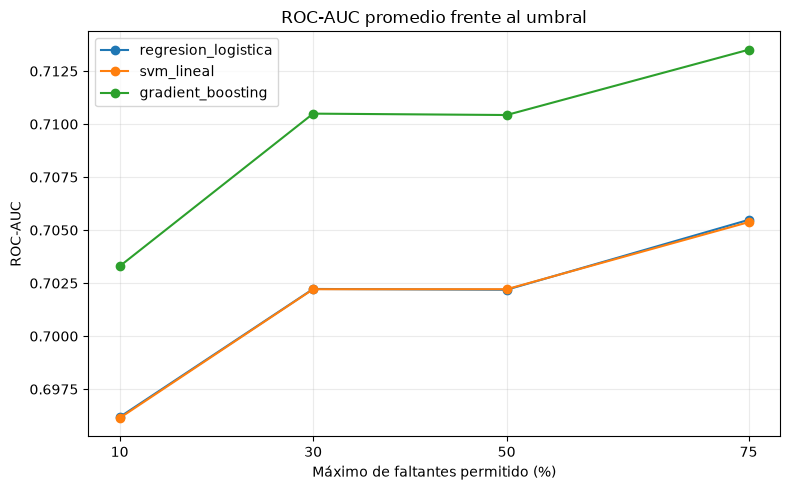

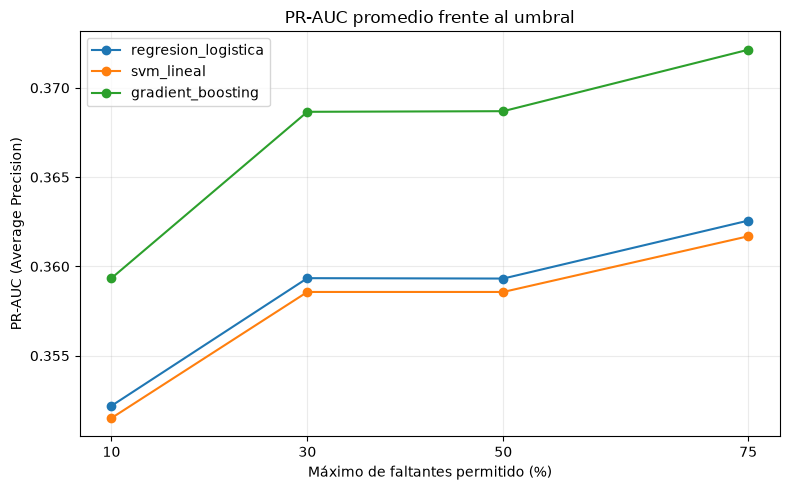

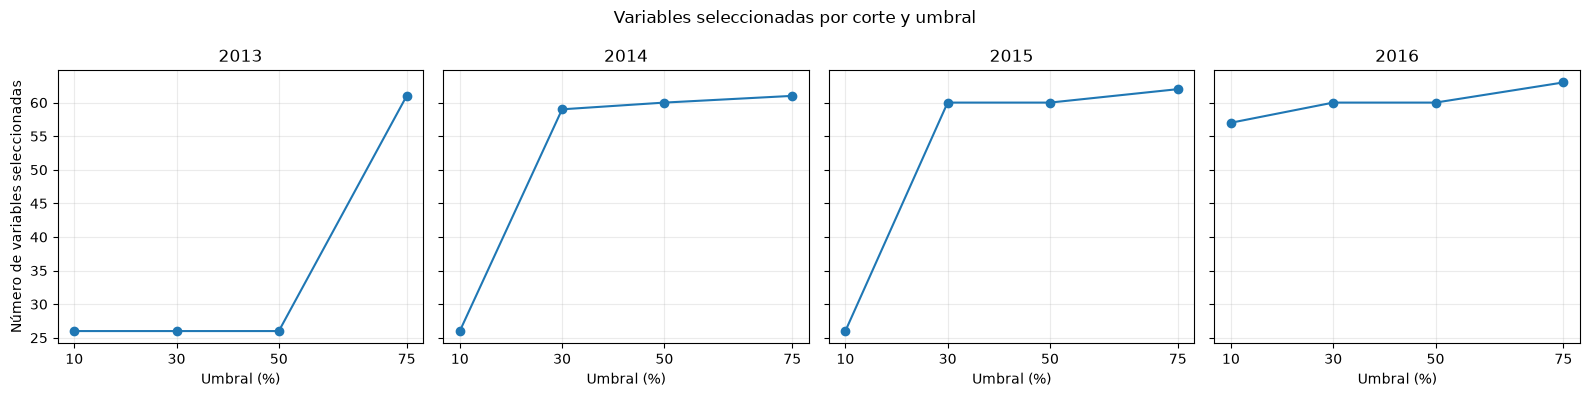

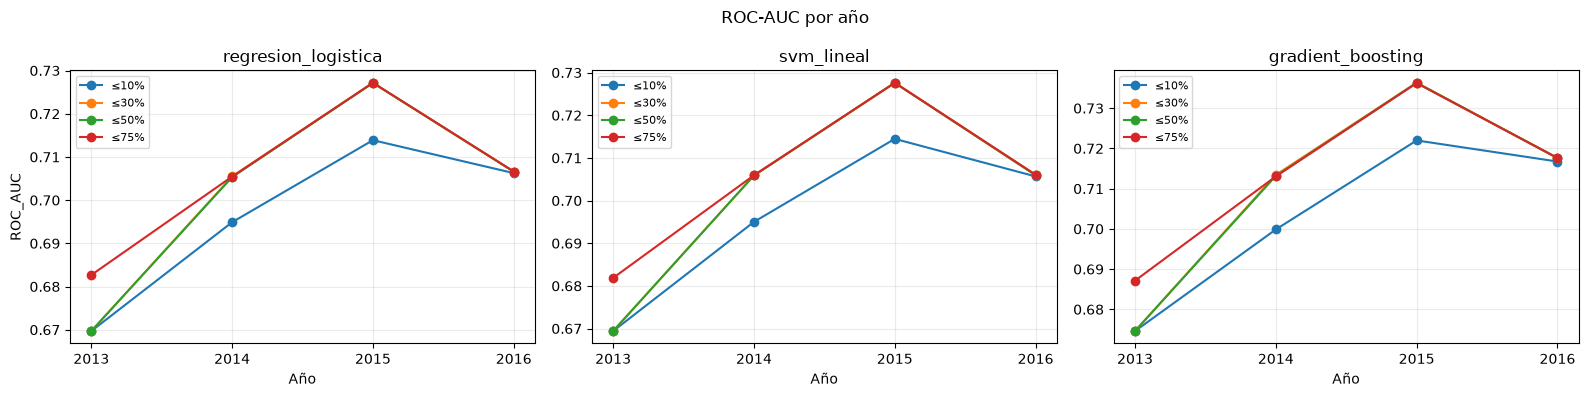

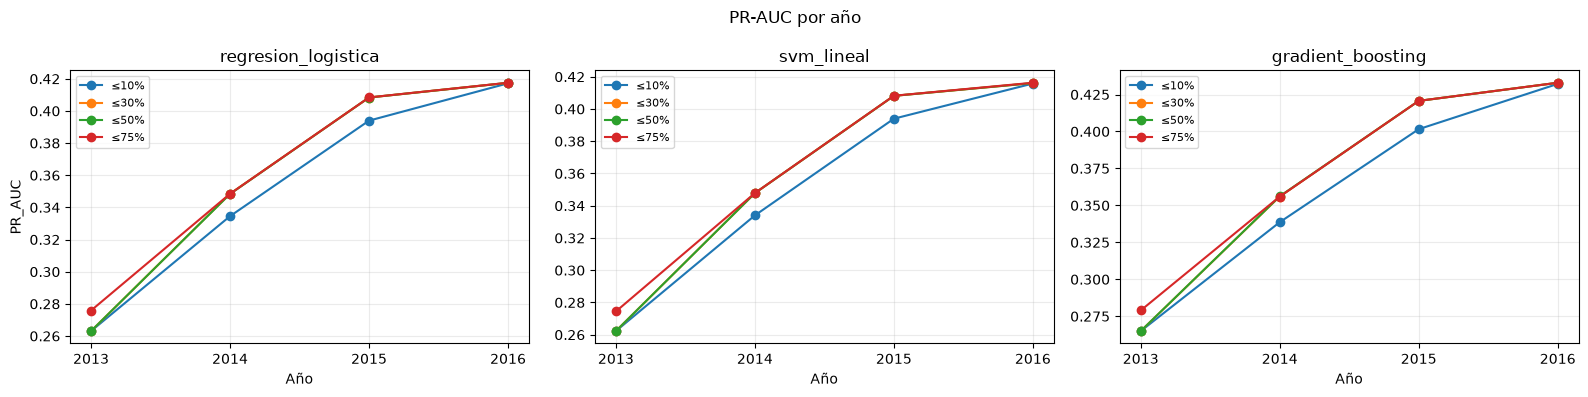

Resultados guardados en: C:\Users\josue\Proyecto-ML-Grupo8\outputs\comparacion_umbrales_faltantes
regresion_logistica: umbral con mayor ROC-AUC promedio ≤75% (ROC=0.70548, PR=0.36256, vars promedio=61.8, desviación ROC=0.01819).
svm_lineal: umbral con mayor ROC-AUC promedio ≤75% (ROC=0.70537, PR=0.36169, vars promedio=61.8, desviación ROC=0.01869).
gradient_boosting: umbral con mayor ROC-AUC promedio ≤75% (ROC=0.71351, PR=0.37213, vars promedio=61.8, desviación ROC=0.02025).


In [2]:
# Los 48 ajustes ya guardados se reutilizan para poder regenerar tablas y gráficos
# sin volver a entrenar los modelos. El detalle de selección se deduplica por clave.
resultados=pd.read_csv(RAIZ/"outputs"/"comparacion_umbrales_parcial.csv")
selecciones=pd.read_csv(RAIZ/"outputs"/"selecciones_umbrales_parcial.csv")
selecciones=selecciones.drop_duplicates(["anio_validacion","umbral_pct","variable"],keep="first").reset_index(drop=True)
resumen=(resultados.groupby(["modelo","umbral_pct"],as_index=False)
 .agg(variables_promedio=("variables_originales","mean"),variables_min=("variables_originales","min"),variables_max=("variables_originales","max"),
      ROC_AUC_promedio=("ROC_AUC","mean"),ROC_AUC_desviacion=("ROC_AUC","std"),
      PR_AUC_promedio=("PR_AUC","mean"),PR_AUC_desviacion=("PR_AUC","std"),
      columnas_transformadas_promedio=("columnas_transformadas","mean"),cortes_convergencia=("advertencia_convergencia","sum")))
resumen[["ROC_AUC_desviacion","PR_AUC_desviacion"]]=resumen[["ROC_AUC_desviacion","PR_AUC_desviacion"]].fillna(0)

# Referencias publicadas en los análisis anteriores; 59 sigue siendo exploratorio.
referencias=pd.DataFrame([
 {"modelo":"regresion_logistica","variables":"26 fijas","ROC_AUC":0.6927,"tipo":"referencia anterior"},
 {"modelo":"regresion_logistica","variables":"59 exploratorias","ROC_AUC":0.7054,"tipo":"exploratoria, selección hasta 2016"},
 {"modelo":"svm_lineal","variables":"26 fijas","ROC_AUC":0.6926,"tipo":"referencia anterior"},
 {"modelo":"svm_lineal","variables":"59 exploratorias","ROC_AUC":0.7052,"tipo":"exploratoria, selección hasta 2016"},
 {"modelo":"gradient_boosting","variables":"26 fijas","ROC_AUC":0.7000,"tipo":"referencia anterior"},
 {"modelo":"gradient_boosting","variables":"59 exploratorias","ROC_AUC":0.7131,"tipo":"exploratoria, selección hasta 2016"},
])
display(resumen.round(5))
display(referencias)

comparacion_referencias=[]
for _,fila in resumen.iterrows():
    refs=referencias[referencias.modelo==fila.modelo]
    for _,ref in refs.iterrows():
        comparacion_referencias.append({
            "modelo":fila.modelo,"umbral_pct":int(fila.umbral_pct),
            "variables_promedio":float(fila.variables_promedio),
            "ROC_AUC_umbral":float(fila.ROC_AUC_promedio),
            "referencia":ref["variables"],"tipo_referencia":ref["tipo"],
            "ROC_AUC_referencia":float(ref["ROC_AUC"]),
            "diferencia_ROC_AUC":float(fila.ROC_AUC_promedio-ref["ROC_AUC"]),
        })
comparacion_referencias=pd.DataFrame(comparacion_referencias)
display(comparacion_referencias.round(5))

# Métricas por año y cortes de variables seleccionadas/excluidas.
display(resultados.sort_values(["modelo","umbral_pct","anio_validacion"])[["modelo","umbral_pct","anio_validacion","variables_originales","ROC_AUC","PR_AUC","advertencia_convergencia"]].round(5))
conteos=(selecciones.groupby(["anio_validacion","umbral_pct","decision"],as_index=False).size()
         .pivot(index=["anio_validacion","umbral_pct"],columns="decision",values="size").fillna(0).reset_index())
display(conteos)

salida=RAIZ/"outputs"/"comparacion_umbrales_faltantes"
salida.mkdir(parents=True,exist_ok=True)

# Gráfico 1: ROC-AUC promedio por umbral y modelo.
fig,ax=plt.subplots(figsize=(8,5))
for modelo in ["regresion_logistica","svm_lineal","gradient_boosting"]:
 s=resumen[resumen.modelo==modelo].sort_values("umbral_pct")
 ax.plot(s.umbral_pct,s.ROC_AUC_promedio,marker="o",label=modelo)
ax.set(title="ROC-AUC promedio frente al umbral",xlabel="Máximo de faltantes permitido (%)",ylabel="ROC-AUC")
ax.set_xticks(UMBRALES); ax.grid(alpha=.25); ax.legend(); fig.tight_layout(); fig.savefig(salida/"01_roc_auc_promedio.png",dpi=160,bbox_inches="tight"); display(fig); plt.close(fig)
# Gráfico 2: PR-AUC promedio.
fig,ax=plt.subplots(figsize=(8,5))
for modelo in ["regresion_logistica","svm_lineal","gradient_boosting"]:
 s=resumen[resumen.modelo==modelo].sort_values("umbral_pct")
 ax.plot(s.umbral_pct,s.PR_AUC_promedio,marker="o",label=modelo)
ax.set(title="PR-AUC promedio frente al umbral",xlabel="Máximo de faltantes permitido (%)",ylabel="PR-AUC (Average Precision)")
ax.set_xticks(UMBRALES); ax.grid(alpha=.25); ax.legend(); fig.tight_layout(); fig.savefig(salida/"02_pr_auc_promedio.png",dpi=160,bbox_inches="tight"); display(fig); plt.close(fig)
# Gráfico 3: número de variables por año y umbral.
fig,axes=plt.subplots(1,4,figsize=(16,4),sharey=True)
for ax,anio in zip(axes,ANIOS_VALIDACION):
 sub=conteos[conteos.anio_validacion==anio].sort_values("umbral_pct")
 ax.plot(sub.umbral_pct,sub.get("conservar",0),marker="o",label="Conservar")
 ax.set_title(str(anio)); ax.set_xticks(UMBRALES); ax.grid(alpha=.25); ax.set_xlabel("Umbral (%)")
axes[0].set_ylabel("Número de variables seleccionadas"); fig.suptitle("Variables seleccionadas por corte y umbral"); fig.tight_layout(); fig.savefig(salida/"03_variables_por_corte.png",dpi=160,bbox_inches="tight"); display(fig); plt.close(fig)
# Gráficos 4 y 5: métricas anuales en paneles separados para cada modelo.
for metrica,titulo in [("ROC_AUC","ROC-AUC por año"),("PR_AUC","PR-AUC por año")]:
 fig,axes=plt.subplots(1,3,figsize=(16,4),sharey=False)
 for ax,modelo in zip(axes,["regresion_logistica","svm_lineal","gradient_boosting"]):
  sub=resultados[resultados.modelo==modelo]
  for umbral in UMBRALES:
   s=sub[sub.umbral_pct==umbral].sort_values("anio_validacion")
   ax.plot(s.anio_validacion,s[metrica],marker="o",label=f"≤{umbral}%")
  ax.set_title(modelo); ax.set_xticks(ANIOS_VALIDACION); ax.set_xlabel("Año")
  ax.grid(alpha=.25); ax.legend(fontsize=8)
 axes[0].set_ylabel(metrica); fig.suptitle(titulo); fig.tight_layout()
 nombre_archivo="04_roc_auc_por_anio.png" if metrica=="ROC_AUC" else "05_pr_auc_por_anio.png"
 fig.savefig(salida/nombre_archivo,dpi=160,bbox_inches="tight"); display(fig); plt.close(fig)

salida=RAIZ/"outputs"/"comparacion_umbrales_faltantes"
salida.mkdir(parents=True,exist_ok=True)
resultados.to_csv(salida/"metricas_por_modelo_umbral_corte.csv",index=False)
resumen.to_csv(salida/"resumen_promedios_y_variabilidad.csv",index=False)
selecciones.to_csv(salida/"variables_seleccionadas_y_excluidas.csv",index=False)
conteos.to_csv(salida/"conteo_variables_por_corte_y_umbral.csv",index=False)
referencias.to_csv(salida/"referencias_experimentos_anteriores.csv",index=False)
comparacion_referencias.to_csv(salida/"comparacion_con_referencias_anteriores.csv",index=False)
tabla_exclusiones.to_csv(salida/"exclusiones_por_disponibilidad_y_alcance.csv",index=False)
print("Resultados guardados en:",salida)

# Resumen comparativo y cautela sobre selección entre varios umbrales.
for modelo in ["regresion_logistica","svm_lineal","gradient_boosting"]:
 s=resumen[resumen.modelo==modelo].sort_values("ROC_AUC_promedio",ascending=False)
 top=s.iloc[0]
 print(f"{modelo}: umbral con mayor ROC-AUC promedio ≤{int(top.umbral_pct)}% (ROC={top.ROC_AUC_promedio:.5f}, PR={top.PR_AUC_promedio:.5f}, vars promedio={top.variables_promedio:.1f}, desviación ROC={top.ROC_AUC_desviacion:.5f}).")


## 4. Conclusiones

La selección se hizo en cada corte usando solo el entrenamiento, y la misma lista se aplicó a su año de validación. Al comparar varios umbrales sobre los mismos cuatro años, los resultados sirven para decidir qué probar después, pero no son una evaluación final independiente. Los años 2017 en adelante no se utilizaron.

El umbral de **10 %** es restrictivo: retiene menos características y obtiene resultados inferiores a los umbrales más amplios. Los umbrales de **30 % y 50 %** producen resultados casi iguales porque seleccionan conjuntos muy parecidos. El de **75 %** obtiene el mayor ROC-AUC y PR-AUC promedio en los tres modelos, con variación entre años comparable o menor que las alternativas de 30 % y 50 %.

| Modelo | Umbral con mayor ROC-AUC promedio | Variables promedio | ROC-AUC promedio | PR-AUC promedio |
|---|---:|---:|---:|---:|
| Regresión logística | 75 % | 61.75 | 0.70548 | 0.36256 |
| SVM lineal | 75 % | 61.75 | 0.70537 | 0.36169 |
| Gradient Boosting | 75 % | 61.75 | 0.71351 | 0.37213 |

El umbral del 75 % se aproxima y supera ligeramente los valores de referencia de 59 características para los tres modelos. Esa comparación es orientativa: aquellos resultados de 59 variables usaron información de faltantes hasta 2016, mientras que aquí la selección se vuelve a calcular exclusivamente con entrenamiento en cada corte.

**Recomendación provisional:** continuar con el umbral de 75 % para los tres algoritmos. En estos cortes, incluir variables con más faltantes no perjudicó la discriminación; aun así, su utilidad puede depender del periodo y no se debe interpretar como un óptimo universal. Antes de fijar la decisión final, se puede volver a optimizar hiperparámetros con esta preparación y reservar el conjunto de prueba para una sola evaluación al final.


## Referencias

scikit-learn developers. (s. f.). *Pipeline and composite estimators*. scikit-learn User Guide. https://scikit-learn.org/stable/modules/compose.html

scikit-learn developers. (s. f.). *SimpleImputer*. scikit-learn API documentation. https://scikit-learn.org/stable/modules/generated/sklearn.impute.SimpleImputer.html

scikit-learn developers. (s. f.). *OneHotEncoder*. scikit-learn API documentation. https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.OneHotEncoder.html